# LiDAR 스캔 매칭으로 지도 만들기

`lidar_scan.ipynb`로 기록한 로그(`.npz`)를 읽어서 로봇의 이동 경로를 추정하고, 5 cm 점유 격자 지도를 만듭니다. 로봇의 Jupyter에서 실행합니다. `scanmatch.py`가 같은 폴더에 있어야 합니다.

## 하는 일
1. 회전별 각도·거리를 로봇 기준 (x 앞, y 왼쪽) 점으로 바꿉니다. 거리 0.15~6.0 m의 점만 씁니다.
2. 새 스캔을 최근 키프레임 10개로 만든 지도에 맞춥니다(point-to-line ICP). 이것이 스캔 매칭입니다.
3. 추정한 경로를 따라 점유 격자 지도를 쌓습니다.
4. 줄자로 잰 이동 거리와 비교합니다.

## 한계
- LiDAR만 사용합니다. 엔코더와 IMU는 쓰지 않습니다(IMU는 값이 항상 0이었습니다).
- 루프 클로저와 전역 최적화가 없으므로 SLAM 전체가 아니라 앞단(스캔 매칭과 지도 작성)까지입니다.
- 2D 평면 하나만 봅니다. 양옆이 평행한 긴 복도처럼 특징이 없는 곳에서는 앞뒤 이동을 구할 수 없습니다.
- 정답 위치를 아는 기록은 줄자로 잰 시작·끝 거리뿐입니다. 한 번의 기록이라 정확도를 단정할 수 없습니다.


In [1]:
LOG = 'lidar_scan_1.npz'    # lidar_scan.ipynb로 기록한 파일
MEASURED_CM = 151.5          # 줄자로 잰 이동 거리(cm). 모르면 None
OUT_PNG = LOG.replace('.npz', '_map.png')

In [2]:
import time
import numpy as np
import scanmatch as sm

d = np.load(LOG)
t, off, a, r = d['t'], d['offsets'], d['angle_deg'], d['dist_mm']
n = len(t)
scans = [sm.polar_to_xy(a[off[i]:off[i+1]], r[off[i]:off[i+1]]) for i in range(n)]
print(f"{LOG}: 회전 {n}회, 기록 시간 {t[-1] - t[0]:.1f}초, 회전당 평균 {np.mean([len(s) for s in scans]):.0f}점(0.15~6 m 안)")

lidar_scan_1.npz: 회전 301회, 기록 시간 29.9초, 회전당 평균 378점(0.15~6 m 안)


In [3]:
t0 = time.time()
poses, infos, failed = sm.run_scan_matching(scans)
t1 = time.time()
L, (xmin, ymin, res) = sm.build_occupancy(scans, poses, res=0.05, max_r=6.0, every=2)
t2 = time.time()

inl = np.array([x['inlier_frac'] for x in infos])
obs = np.array([x['trans_min_eig'] for x in infos])
print(f"스캔 매칭 {t1 - t0:.1f}초 (스캔당 {(t1 - t0) / n * 1000:.0f} ms), 지도 만들기 {t2 - t1:.1f}초")
print(f"매칭 실패 {sum(failed)}회 | 겹침 비율(inlier) 중앙 {np.median(inl):.2f}, 최소 {inl.min():.2f}")
print(f"이동 관측성(trans_min_eig) 중앙 {np.median(obs):.2f}, 최소 {obs.min():.2f}  (0.1 미만이면 앞뒤 이동을 믿을 수 없음)")

스캔 매칭 4.8초 (스캔당 16 ms), 지도 만들기 19.2초
매칭 실패 0회 | 겹침 비율(inlier) 중앙 0.95, 최소 0.82
이동 관측성(trans_min_eig) 중앙 0.30, 최소 0.22  (0.1 미만이면 앞뒤 이동을 믿을 수 없음)


In [4]:
disp_cm = np.hypot(*(poses[-1, :2] - poses[0, :2])) * 100
print(f"스캔 매칭 추정 이동 거리: {disp_cm:.1f} cm")
if MEASURED_CM is not None:
    print(f"줄자 실측: {MEASURED_CM} cm  ->  차이 {disp_cm - MEASURED_CM:+.1f} cm ({(disp_cm / MEASURED_CM - 1) * 100:+.1f}%)")
print(f"끝 위치 옆으로 {poses[-1, 1] * 100:+.1f} cm, 방향 변화 {np.degrees(poses[-1, 2]):+.1f}°")

스캔 매칭 추정 이동 거리: 145.7 cm
줄자 실측: 151.5 cm  ->  차이 -5.8 cm (-3.8%)
끝 위치 옆으로 +3.2 cm, 방향 변화 -2.7°


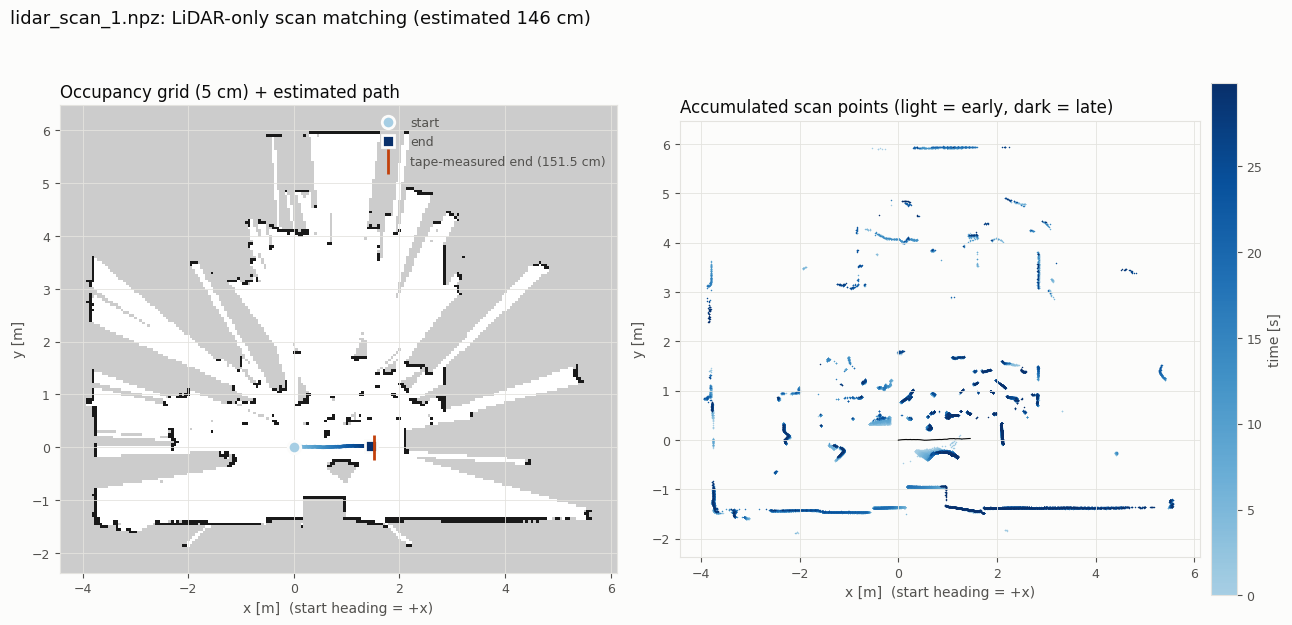

저장: lidar_scan_1_map.png


In [5]:
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, ListedColormap

SURFACE, INK, INK2, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#e4e3df'
tt = t - t[0]
img = np.full(L.shape, 0.80); img[L < -0.5] = 1.0; img[L > 0.8] = 0.10
H, W = L.shape
extent = (xmin, xmin + W * res, ymin, ymin + H * res)
blues = matplotlib.colormaps['Blues']; norm = Normalize(0, tt[-1])

fig, axs = plt.subplots(1, 2, figsize=(13, 6.2), facecolor=SURFACE)
for ax in axs:
    ax.set_facecolor(SURFACE); ax.set_aspect('equal')
    for s in ax.spines.values(): s.set_color(GRID)
    ax.tick_params(colors=INK2, labelsize=9); ax.grid(color=GRID, lw=0.6)
    ax.set_xlabel('x [m]  (start heading = +x)', color=INK2); ax.set_ylabel('y [m]', color=INK2)

ax = axs[0]
ax.imshow(img, cmap='gray', vmin=0, vmax=1, origin='lower', extent=extent, interpolation='nearest')
for i in range(n - 1):
    ax.plot(poses[i:i+2, 0], poses[i:i+2, 1], color=blues(0.35 + 0.65 * norm(tt[i])), lw=2.4, solid_capstyle='round')
ax.plot(*poses[0, :2], 'o', ms=9, mfc=blues(0.35), mec=SURFACE, mew=2, label='start')
ax.plot(*poses[-1, :2], 's', ms=9, mfc=blues(1.0), mec=SURFACE, mew=2, label='end')
if MEASURED_CM is not None:
    ax.plot(MEASURED_CM / 100, 0, marker='|', ms=18, mew=2, color='#c2410c', ls='none',
            label=f'tape-measured end ({MEASURED_CM} cm)')
ax.set_title('Occupancy grid (5 cm) + estimated path', color=INK, fontsize=12, loc='left')
ax.legend(loc='upper right', frameon=False, labelcolor=INK2, fontsize=9)

ax = axs[1]
for i in range(0, n, 3):
    w = sm.transform(scans[i], poses[i])
    ax.scatter(w[:, 0], w[:, 1], s=1.2, color=blues(0.35 + 0.65 * norm(tt[i])), linewidths=0)
ax.plot(poses[:, 0], poses[:, 1], color=INK, lw=0.8)
ax.set_xlim(*axs[0].get_xlim()); ax.set_ylim(*axs[0].get_ylim())
ax.set_title('Accumulated scan points (light = early, dark = late)', color=INK, fontsize=12, loc='left')
cb = fig.colorbar(matplotlib.cm.ScalarMappable(norm=norm, cmap=ListedColormap(blues(np.linspace(0.35, 1, 256)))),
                  ax=ax, fraction=0.046, pad=0.02)
cb.set_label('time [s]', color=INK2); cb.ax.tick_params(colors=INK2, labelsize=9); cb.outline.set_edgecolor(GRID)

fig.suptitle(f'{LOG}: LiDAR-only scan matching (estimated {disp_cm:.0f} cm)', color=INK, fontsize=13, x=0.01, ha='left')
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(OUT_PNG, dpi=150, facecolor=SURFACE)
plt.show()
print('저장:', OUT_PNG)